# Notebook 02 - Data Preparation and Feature Engineering

**Goal:** turn the audited raw data into a leak-free modelling setup:

1. clean the data (duplicates, missing target),
2. split into train and test **before** anything is learned from the data,
3. build features and check by experiment that they help,
4. show the single preprocessing pipeline that every model will use.

**Why the order matters:** anything that learns from data (medians, scaling, category lists) must learn from the *training* rows only.
If the test rows influence those steps, the test score becomes too optimistic (data leakage).

In [ ]:
import os, sys, warnings
from pathlib import Path

# Work from the project root whether the notebook is opened from the root or from notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
print("Project root:", ROOT)

In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score

from src.data_utils import (load_raw, validate, clean, get_split, iqr_outlier_counts,
                            RAW_FEATURES, TARGET, ID_COL, RANDOM_STATE)
from src.features import add_features, ALL_ENGINEERED
from src.pipeline import build_pipeline, build_preprocessor
from src import plots

## 1. Clean the data

`clean()` drops rows with a missing target and removes duplicate customers (ignoring the ID column). On this dataset it should change
nothing, because the audit in notebook 01 found no such rows. We still run it and *check* that, instead of assuming.

In [3]:
raw = load_raw()
df = clean(raw)
print("Rows before cleaning:", len(raw), "| after cleaning:", len(df), "| rows removed:", len(raw) - len(df))
print("Missing values left:", int(df.isnull().sum().sum()))

Rows before cleaning: 10000 | after cleaning: 10000 | rows removed: 0
Missing values left: 0


## 2. Outliers - decision

Notebook 01 found IQR outliers in some columns and decided to keep them because the values are plausible. Here we only restate the
detection table; no rows are removed.

In [4]:
display(iqr_outlier_counts(raw))
print("Rows removed because of outliers: 0 (decision recorded in docs/decisions.md)")

,column,lower_bound,upper_bound,n_outliers,pct,min,max
0,credit_score,383.00000,919.00000,15,0.15,350.00,850.00
1,age,14.00000,62.00000,359,3.59,18.00,92.00
2,tenure,-3.00000,13.00000,0,0.00,0.00,10.00
3,balance,-191466.36000,319110.60000,0,0.00,0.00,250898.09
4,estimated_salary,-96577.09625,296967.45375,0,0.00,11.58,199992.48


Rows removed because of outliers: 0 (decision recorded in docs/decisions.md)


## 3. Train / test split (before any fitting)

A stratified 80/20 split with a fixed random seed. The model inputs are the raw columns only: `customer_id` and the target are not in `X`.

In [5]:
X_train, X_test, y_train, y_test = get_split(df)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train:", round(y_train.mean(), 4), " test:", round(y_test.mean(), 4))
print("Columns used as input:", list(X_train.columns))
print("customer_id in inputs?", ID_COL in X_train.columns)
print("Rows shared between train and test:", len(set(X_train.index) & set(X_test.index)))

# Save the two splits so the work is reproducible and inspectable
out_dir = ROOT / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
X_train.assign(churn=y_train).to_csv(out_dir / "train.csv", index=False)
X_test.assign(churn=y_test).to_csv(out_dir / "test.csv", index=False)
print("Saved data/processed/train.csv and test.csv")

Train: (8000, 10) | Test: (2000, 10)
Churn rate  train: 0.2037  test: 0.2035
Columns used as input: ['credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary']
customer_id in inputs? False
Rows shared between train and test: 0
Saved data/processed/train.csv and test.csv


## 4. Feature engineering

`add_features` (in `src/features.py`) creates four features. It only uses values from the **same row**, so it cannot leak anything
from other rows. Look at what it adds:

In [6]:
display(add_features(X_train).loc[:, ["balance", "estimated_salary", "products_number", "age"] + ALL_ENGINEERED].head(8))

,balance,estimated_salary,products_number,age,balance_to_salary,balance_zero,many_products,age_group
2151,0.00,159475.08,1,57,0.000000,1,0,51-60
8392,102128.27,63981.37,1,32,1.596194,0,0,31-40
5006,113865.23,117396.25,2,37,0.969914,0,0,31-40
4117,0.00,83093.25,2,37,0.000000,1,0,31-40
7182,110540.43,107472.99,2,49,1.028532,0,0,41-50
3522,0.00,132809.18,2,38,0.000000,1,0,31-40
8783,0.00,183021.06,1,34,0.000000,1,0,31-40
741,156325.38,125381.02,1,24,1.246793,0,0,<=30


| Feature | What it is | Why we try it |
|---|---|---|
| `balance_zero` | 1 if the balance is exactly 0 | zero-balance customers are a large group with a different churn rate |
| `balance_to_salary` | balance / (salary + 1) | how much of a customer's income is held at this bank |
| `many_products` | 1 if 3 or more products | those customers behave very differently from 1-2 products |
| `age_group` | age bands: <=30, 31-40, 41-50, 51-60, 60+ | churn is not a straight line in age |

## 5. Do the engineered features actually help? (ablation test)

Making a feature is not enough - we test it. For a simple model (Logistic Regression) and a tree model (Random Forest) we compare
5-fold cross-validated ROC-AUC on the **training data only** for: no engineered features, each feature alone, and all four together.
Differences smaller than the fold-to-fold spread (the `+/-` value) should be treated as noise.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

configs = {"none": []}
configs.update({f: [f] for f in ALL_ENGINEERED})
configs["all"] = list(ALL_ENGINEERED)

ablation = {}
for model_name, params in [("Logistic Regression", {}), ("Random Forest", {"n_estimators": 150})]:
    ablation[model_name] = {}
    for cfg_name, feats in configs.items():
        t = time.time()
        pipe = build_pipeline(model_name, engineered=feats, **params)
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
        ablation[model_name][cfg_name] = {"cv_roc_auc_mean": float(scores.mean()),
                                          "cv_roc_auc_std": float(scores.std())}
        print(f"{model_name:20s} {cfg_name:18s} AUC = {scores.mean():.4f} +/- {scores.std():.4f}  ({time.time()-t:.0f}s)")

(ROOT / "models").mkdir(exist_ok=True)
(ROOT / "models" / "feature_ablation.json").write_text(json.dumps(ablation, indent=2))

Logistic Regression  none               AUC = 0.7628 +/- 0.0199  (1s)


Logistic Regression  balance_to_salary  AUC = 0.7629 +/- 0.0201  (0s)


Logistic Regression  balance_zero       AUC = 0.7625 +/- 0.0205  (0s)


Logistic Regression  many_products      AUC = 0.8304 +/- 0.0120  (0s)


Logistic Regression  age_group          AUC = 0.7834 +/- 0.0190  (0s)


Logistic Regression  all                AUC = 0.8415 +/- 0.0112  (0s)


... (3 outputs left out)

Random Forest        many_products      AUC = 0.8481 +/- 0.0127  (6s)


Random Forest        age_group          AUC = 0.8453 +/- 0.0135  (7s)


Random Forest        all                AUC = 0.8501 +/- 0.0144  (7s)


1455

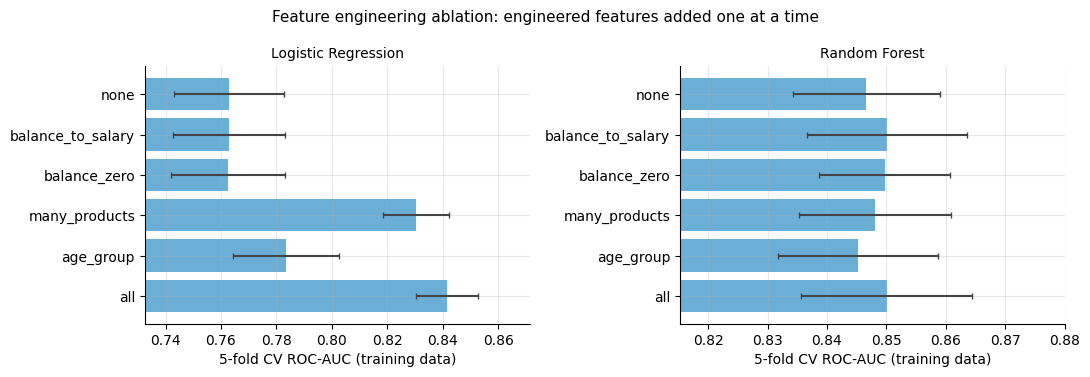

In [8]:
fig = plots.feature_ablation_plot(ablation)
fig.savefig(ROOT / "reports" / "figures" / "13_feature_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** compare the `none` row with the `all` row for each model, and look at which single feature moves the score.
A feature that does not beat the noise level is a weak reason to keep it by itself. We keep all four because the combined set is best
(or equal) for both models and none of them hurts - the evidence is in the output above.

## 6. The preprocessing pipeline every model will use

Everything below is **fitted on the training data only** when a model is trained. The same pipeline object is saved with the model,
so the Streamlit app applies exactly the same steps to a new customer.

| Step | Columns | What it does |
|---|---|---|
| Feature engineering | all raw inputs | adds the four engineered columns |
| Numeric | credit_score, age, tenure, balance, estimated_salary, products_number, balance_to_salary | fill missing with the median, then standardise (needed for Logistic Regression, KNN and SVM) |
| Categorical | country, gender, age_group | fill missing with the most frequent value, then one-hot encode (unseen categories are ignored safely) |
| Binary | credit_card, active_member, balance_zero, many_products | passed through (missing filled with the most frequent value) |

In [9]:
prep_pipe = build_pipeline("Logistic Regression")
transformed = prep_pipe[:-1].fit_transform(X_train)                   # steps 1-2, fitted on TRAIN only
print("Training matrix after preprocessing:", transformed.shape)
try:
    names = prep_pipe.named_steps["prep"].get_feature_names_out()
    print(len(names), "columns:", list(names))
except Exception as e:
    print("(feature names not available:", e, ")")

# Sanity check: the scaler learned from training rows only
scaler = prep_pipe.named_steps["prep"].named_transformers_["num"].named_steps["scale"]
print("Scaler mean for credit_score (from TRAIN only):", round(scaler.mean_[0], 2),
      "| TRAIN column mean:", round(X_train["credit_score"].mean(), 2),
      "| whole-dataset mean:", round(df["credit_score"].mean(), 2))

Training matrix after preprocessing: (8000, 21)
21 columns: ['num__credit_score', 'num__age', 'num__tenure', 'num__balance', 'num__estimated_salary', 'num__products_number', 'num__balance_to_salary', 'cat__country_France', 'cat__country_Germany', 'cat__country_Spain', 'cat__gender_Female', 'cat__gender_Male', 'cat__age_group_31-40', 'cat__age_group_41-50', 'cat__age_group_51-60', 'cat__age_group_60+', 'cat__age_group_<=30', 'bin__credit_card', 'bin__active_member', 'bin__balance_zero', 'bin__many_products']
Scaler mean for credit_score (from TRAIN only): 650.75 | TRAIN column mean: 650.75 | whole-dataset mean: 650.53


## 7. Summary

* The data needed no repairs (no missing values or duplicates); the cleaning steps are still in place and tested.
* The split happened before any fitting; train and test have the same churn rate (stratified).
* Four engineered features were created and tested; the evidence is in the ablation table.
* One pipeline (features -> impute -> scale/encode -> model) is shared by all models; notebook 03 trains, tunes, compares and saves them.